# Tendencias de contratación pública TI (2025–2026)

**Período previsto:** enero de 2025–octubre de 2026 (22 meses completos).

Este informe reúne los resúmenes mensuales generados por el analizador de PLACSP. Describe los resultados observados en licitaciones de perfiles alojados en la plataforma; no estima el mercado completo ni confirma relaciones entre expedientes. Noviembre de 2026 queda fuera porque el mes aún no ha cerrado.

## Método y lectura de las métricas

El analizador trabaja con los ZIP mensuales de la sindicicación 643 y delimita cada corte por `atom:updated`. Para cada expediente toma la última versión observada dentro del mes. Sus `TenderResult` pueden corresponder a lotes, por lo que las métricas de resultados y ofertas se interpretan como lotes/resultados y no necesariamente como expedientes únicos.

Desde `radar-oportunidades`, instala los paquetes con `python -m pip install -r notebooks/requirements-notebook.txt` y registra el kernel con `python -m ipykernel install --user --name radar-oportunidades --display-name "Python (.venv Radar)"`. En Jupyter selecciona **Python (.venv Radar)** como kernel.

- **Desiertos globales:** lotes con código 3 / lotes con resultado resuelto (códigos 3, 4, 5, 8 y 9).
- **Una oferta global:** resultados numéricos con exactamente una oferta / resultados con ofertas numéricas.
- **Cobertura de ofertas:** resultados con campo de ofertas no vacío / resultados de lote en la última versión.
- **CPV 72 y 48:** expedientes únicos con esos códigos, por CPV principal o por cualquier CPV, respectivamente.
- **Baja concurrencia TI:** en CPV 72/48, lote desierto o lote adjudicado/formalizado (códigos 8/9) con 0 o 1 ofertas; el resumen también informa la mediana de ofertas numéricas de lotes adjudicados. Los códigos 3 y 4 se excluyen como negociados en la vista `sin_negociados`; su correspondencia requiere confirmación contra el catálogo oficial.

> Los candidatos a relicitación son coincidencias heurísticas para revisión, no relaciones confirmadas. Las cifras de meses dependen de la cobertura de cada ZIP; no hay manifiesto independiente para probar exhaustividad.

In [3]:
from calendar import month_abbr
from datetime import date
import json
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import pandas as pd

print(f'Kernel Python: {sys.executable}')

# Encuentra la raíz tanto si Jupyter se abrió desde notebooks/ como desde el repo.
candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_DIR = next((p for p in candidates if (p / 'src' / 'radar_oportunidades').is_dir()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('Abre este notebook desde el repositorio Radar o uno de sus subdirectorios.')
DATA_DIR = PROJECT_DIR / 'data'

# Serie acordada: año 2025 completo y meses completos de 2026 hasta octubre.
MONTHS = [f'{year}{month:02d}' for year in (2025, 2026) for month in range(1, 13) if year == 2025 or month <= 10]
records, missing, old_schema = [], [], []
for yyyymm in MONTHS:
    summary_path = DATA_DIR / f'salida_{yyyymm}' / f'resumen_643_{yyyymm}.json'
    if not summary_path.is_file():
        missing.append(yyyymm)
        continue
    with summary_path.open(encoding='utf-8') as stream:
        item = json.load(stream)
    if item.get('periodo_analizado_por_updated') != f'{yyyymm[:4]}-{yyyymm[4:]}':
        raise ValueError(f'El período del resumen no coincide con {summary_path}')
    ti = item.get('concurrencia_ti_cpv_72_48', {})
    if not ti:
        old_schema.append(yyyymm)
    total_ti = ti.get('total', {})
    comparable_ti = ti.get('sin_negociados', {})
    records.append({
        'mes': f'{yyyymm[:4]}-{yyyymm[4:]}', 'yyyymm': yyyymm,
        'lotes_resultado': item.get('resultados_lotes_ultima_version'),
        'lotes_resueltos': item.get('resultados_resueltos_codigos_3_4_5_8_9'),
        'desiertos': item.get('desiertos_codigo_3'),
        'pct_desiertos': item.get('porcentaje_desiertos_sobre_resultados_resueltos'),
        'ofertas_una': item.get('resultados_con_una_oferta'),
        'pct_una_oferta': item.get('porcentaje_una_oferta_sobre_ofertas_numericas'),
        'pct_cobertura_ofertas': item.get('cobertura_ofertas_sobre_resultados_lotes'),
        'cpv72_principal': item.get('cpv_division_72_principal'),
        'cpv72_cualquier': item.get('cpv_division_72_cualquier_cpv'),
        'cpv48_principal': item.get('cpv_division_48_principal'),
        'cpv48_cualquier': item.get('cpv_division_48_cualquier_cpv'),
        'ti_baja_concurrencia_pct': total_ti.get('pct_baja_concurrencia'),
        'ti_baja_concurrencia_sin_negociados_pct': comparable_ti.get('pct_baja_concurrencia'),
        'ti_lotes_resueltos': total_ti.get('lotes_resueltos_3_8_9'),
        'ti_mediana_ofertas': total_ti.get('mediana_ofertas'),
        'candidatos_relicitacion': item.get('candidatos_relicitacion_heuristica_titulo_organo_cpv'),
    })

expected_months = pd.PeriodIndex(MONTHS, freq='M')
df = pd.DataFrame(records)
if not df.empty:
    df['periodo'] = pd.PeriodIndex(df['mes'], freq='M')
    df = df.sort_values('periodo').reset_index(drop=True)

print(f'Meses esperados: {len(MONTHS)} | disponibles: {len(df)} | ausentes: {len(missing)}')
if missing:
    warnings.warn('Faltan resúmenes para: ' + ', '.join(missing), stacklevel=1)
if old_schema:
    warnings.warn('Estos resúmenes no incluyen las métricas TI del analizador actualizado y deben regenerarse: ' + ', '.join(old_schema), stacklevel=1)
if df.empty:
    print('Añade los JSON mensuales a data/salida_AAAAMM/ y vuelve a ejecutar el notebook.')
else:
    display(df.drop(columns=['yyyymm', 'periodo']).set_index('mes'))

Kernel Python: d:\20-29 EDUCACION\22 Master Evolve\Máster II\TFM\tfm-evolve-data-ai\radar-oportunidades\.venv\Scripts\python.exe
Meses esperados: 22 | disponibles: 22 | ausentes: 0


,lotes_resultado,lotes_resueltos,desiertos,pct_desiertos,ofertas_una,pct_una_oferta,pct_cobertura_ofertas,cpv72_principal,cpv72_cualquier,cpv48_principal,cpv48_cualquier,ti_baja_concurrencia_pct,ti_baja_concurrencia_sin_negociados_pct,ti_lotes_resueltos,ti_mediana_ofertas,candidatos_relicitacion
mes,,,,,,,,,,,,,,,,
2025-01,29509,29509,2344,7.94,10532,36.04,99.04,1361,1783,594,894,44.65,36.05,1981,2.0,1211
2025-02,29639,29639,2129,7.18,10293,35.03,99.13,1322,1753,777,1073,40.03,32.67,2398,2.0,480
2025-03,29258,29258,2162,7.39,10146,35.08,98.84,1484,1960,637,963,45.93,38.76,1931,2.0,518
2025-04,29189,29188,2142,7.34,10113,34.97,99.08,1475,1948,631,943,45.70,38.39,1930,2.0,582
2025-05,34169,34169,2436,7.13,11859,35.02,99.11,1664,2170,741,1117,46.75,38.60,2107,2.0,420
2025-06,34766,34766,2666,7.67,12486,36.22,99.16,1629,2108,801,1171,47.69,39.89,2082,2.0,2191
2025-07,36869,36869,2920,7.92,13223,36.18,99.12,1690,2209,855,1246,47.25,39.52,2165,2.0,3231
2025-08,27930,27930,2139,7.66,10433,37.67,99.17,1168,1567,590,902,41.21,34.56,1713,2.0,835
2025-09,33786,33786,2697,7.98,12424,37.13,99.04,1519,2046,846,1197,46.77,39.54,2181,2.0,608


## Cobertura de la serie

La tabla y los gráficos incluyen solo meses con JSON disponible. Si faltan meses, la advertencia anterior los enumera; no se interpolan ni se rellenan con cero. Las cantidades de un mes no deben compararse como tendencia sin considerar el volumen y la cobertura del feed.

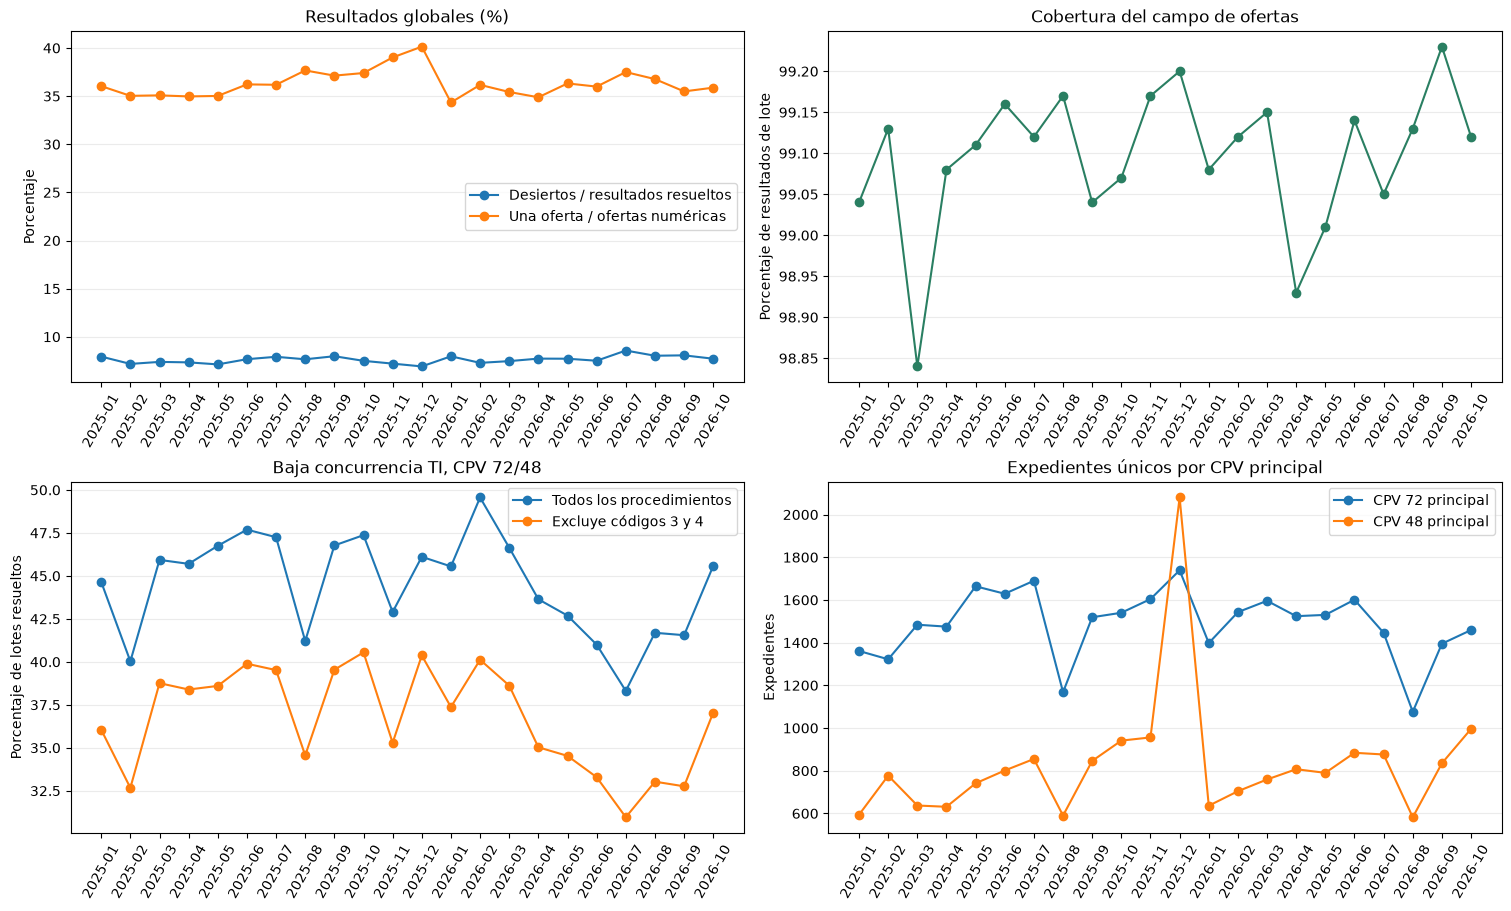

,ti_lotes_resueltos,ti_baja_concurrencia_pct,ti_mediana_ofertas,candidatos_relicitacion
mes,,,,
2025-01,1981,44.65,2.0,1211
2025-02,2398,40.03,2.0,480
2025-03,1931,45.93,2.0,518
2025-04,1930,45.70,2.0,582
2025-05,2107,46.75,2.0,420
2025-06,2082,47.69,2.0,2191
2025-07,2165,47.25,2.0,3231
2025-08,1713,41.21,2.0,835
2025-09,2181,46.77,2.0,608


In [4]:
if not df.empty:
    x = df['mes']
    fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
    axes[0, 0].plot(x, df['pct_desiertos'], marker='o', label='Desiertos / resultados resueltos')
    axes[0, 0].plot(x, df['pct_una_oferta'], marker='o', label='Una oferta / ofertas numéricas')
    axes[0, 0].set_title('Resultados globales (%)')
    axes[0, 0].set_ylabel('Porcentaje')
    axes[0, 0].legend()
    axes[0, 1].plot(x, df['pct_cobertura_ofertas'], marker='o', color='#2a7f62')
    axes[0, 1].set_title('Cobertura del campo de ofertas')
    axes[0, 1].set_ylabel('Porcentaje de resultados de lote')
    axes[1, 0].plot(x, df['ti_baja_concurrencia_pct'], marker='o', label='Todos los procedimientos')
    axes[1, 0].plot(x, df['ti_baja_concurrencia_sin_negociados_pct'], marker='o', label='Excluye códigos 3 y 4')
    axes[1, 0].set_title('Baja concurrencia TI, CPV 72/48')
    axes[1, 0].set_ylabel('Porcentaje de lotes resueltos')
    axes[1, 0].legend()
    axes[1, 1].plot(x, df['cpv72_principal'], marker='o', label='CPV 72 principal')
    axes[1, 1].plot(x, df['cpv48_principal'], marker='o', label='CPV 48 principal')
    axes[1, 1].set_title('Expedientes únicos por CPV principal')
    axes[1, 1].set_ylabel('Expedientes')
    axes[1, 1].legend()
    for ax in axes.flat:
        ax.grid(axis='y', alpha=0.25)
        ax.tick_params(axis='x', rotation=60)
    plt.show()

    display(df[['mes', 'ti_lotes_resueltos', 'ti_baja_concurrencia_pct', 'ti_mediana_ofertas', 'candidatos_relicitacion']].set_index('mes'))

## Interpretación y límites

Interpreta los porcentajes junto a sus denominadores y el número de lotes resueltos. Las cantidades de CPV cuentan expedientes únicos; los resultados de ofertas y concurrencia cuentan lotes/resultados, por lo que no son magnitudes intercambiables. El campo `ReceivedTenderQuantity` describe el dato publicado y no mide por sí solo la competencia efectiva.

La tasa de baja concurrencia combina desiertos y adjudicaciones/formalizaciones con cero o una oferta. La tasa sin negociados depende de la clasificación provisional de los códigos 3 y 4. Los candidatos a relicitación se muestran solo como contexto y nunca como enlaces confirmados. El feed no proporciona un inventario externo con el que demostrar su exhaustividad.

Antes de publicar conclusiones, es necesario completar los 22 resúmenes con la misma versión del analizador y revisa la definición oficial de los códigos de procedimiento.